In [1]:
import numpy as np
import matplotlib.pyplot as plt
import squidpy as sq
import scanpy as sc


from knit.run_test import compute_gram_matrix
from knit.compute_statistic import centre_rows_and_columns

from scipy.sparse.linalg import eigs
from scipy.stats import chi2, norm

In [2]:
fontsize = 12
ms = 5
marker = 'o'
cmap = 'plasma'
marker_list = ['o', 'v', '>' ,'s', '*', 'p',  '^', '<',]
linestyle_list = ['solid', 'dashed', 'dotted', 'dashdot',  (0, (3, 1, 1, 1, 1, 1))]
N_colors = 6
blues = [plt.cm.Blues(i / (N_colors - 1)) for i in range(N_colors)][1:]
capsize = 0
transparency = 1
linewidth = 1.5
alpha_CI = 0.05

In [4]:
def compute_A_B_beta_Bpred(adata, index_train_set, gene, kernel_X = 'gaussian', kernel_Y = 'gaussian', q_X = 0.5, q_Y = 0.5, truncation_X = 1, truncation_e = 1):
    # split the adata into a train and test set
    Y = adata[:,adata.var.index == gene].X.toarray()
    X = adata.obsm['spatial']
    Y_train = Y[index_train_set]
    Y_test = Y[~index_train_set]
    X_train = X[index_train_set]
    X_test = X[~index_train_set]
    n_train = X_train.shape[0]
    n_test = X_test.shape[0]
    
    # Compute Grams
    K_X_train_train = compute_gram_matrix(X_train, X_train, kernel_X, q_X)  
    K_X_test_train = compute_gram_matrix(X_test, X_train, kernel_X, q_X)
    K_Y_train_train = compute_gram_matrix(Y_train, Y_train, kernel_Y, q_Y)
    K_Y_test_test = compute_gram_matrix(Y_test, Y_test, kernel_Y, q_Y)

    # Compute A_tilde
    vals, vecs = eigs((1/n_train**2)*centre_rows_and_columns(K_Y_train_train)@centre_rows_and_columns(K_X_train_train), truncation_X, v0 = np.ones(n_train), which = 'LR')
    A_tilde = vecs.real
    A_tilde = A_tilde/np.sqrt(np.diag((A_tilde.T@centre_rows_and_columns(K_X_train_train)@A_tilde)).reshape(1, -1)) # Normalise so eigenfunctions are unit

    # Compute A - matrix such that A_is = < embX (X_i), f^YX_s >
    A = centre_rows_and_columns(K_X_test_train)@A_tilde

    # Compute P_X 
    P_X = A@np.linalg.inv(A.T@A)@A.T

    # Compute matrix of residues
    L_epsilon = (1/n_test)*centre_rows_and_columns((np.eye(n_test) - P_X)@K_Y_test_test@(np.eye(n_test) - P_X))

    # Compute B_tilde - matrix such that f^{epsilon}_t = sum_i^n B_tilde_it embY(Y_i) for f^{epsilon} eigenvalue of Sigma^{epsilon}
    vals, vecs = eigs(L_epsilon, truncation_e, v0 = np.ones(n_test), which = 'LR')
    B_tilde = vecs.real
    B_tilde= B_tilde/np.sqrt(np.diag(B_tilde.T@centre_rows_and_columns(K_Y_test_test)@B_tilde).reshape(1, -1))

    # Compute B, matrix such that B_it = < embY(Y_i), f^{epsilon}_t >
    B = centre_rows_and_columns(K_Y_test_test)@B_tilde 

    beta = np.linalg.inv(A.T@A)@A.T@B
    Bpred = A@beta


    # Compute P_e
    diag_inv_epsilon = np.diag(vals.real**(-1))
    P_e = (1/n_test)*B@diag_inv_epsilon@B.T

    # Compute Test Stat
    test_stat = n_test*np.trace(P_X@P_e) 

    pval = chi2.sf(test_stat, truncation_e*truncation_X)

    return A, B, beta, Bpred, test_stat, pval

def compute_B_cond_A_bins(A, B, N_bins = 10):
    quantiles = np.linspace(0, 1, N_bins  + 1)
    bins = np.quantile(A, quantiles)
    bins_lower = bins[0: -1]
    bins_upper = bins[1:]

    A_bin_mean = []
    B_bin_mean = []
    B_bin_CI = []
    alpha_CI = 0.05
    for i in range(N_bins):
        B_bin_values = B[((A > bins_lower)*(A < bins_upper))[:,i]]
        if len(B_bin_values) > 0:
            A_bin_mean.append((bins_lower[i] + bins_upper[i])/2)
            B_bin_mean.append(B_bin_values.mean())
            B_bin_CI.append(B_bin_values.std()/np.sqrt(len(B_bin_values))*norm.ppf(1 - alpha_CI/2))

    x = np.array(A_bin_mean)
    y = np.array(B_bin_mean)
    yerr = np.array(B_bin_CI)

    return x, y, yerr
   
def plot_over_tissue(gene, adata, ax, cbar = True, cmap = 'plamsa', tissue = True):
    ax = sq.pl.spatial_scatter(
    adata,  color=gene,
    wspace=0,  colorbar = cbar,  img_res_key='hires', img_alpha = 1*tissue,
    cmap = cmap, shape = 'hex' ,return_ax = True,
    size = 2, ax = ax, title = '')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set(xlabel='', ylabel='')
    return ax

# Figure 6

gene LHB, p-value = 1.7093431684431482e-51
gene CLU, p-value = 2.477545674551646e-157


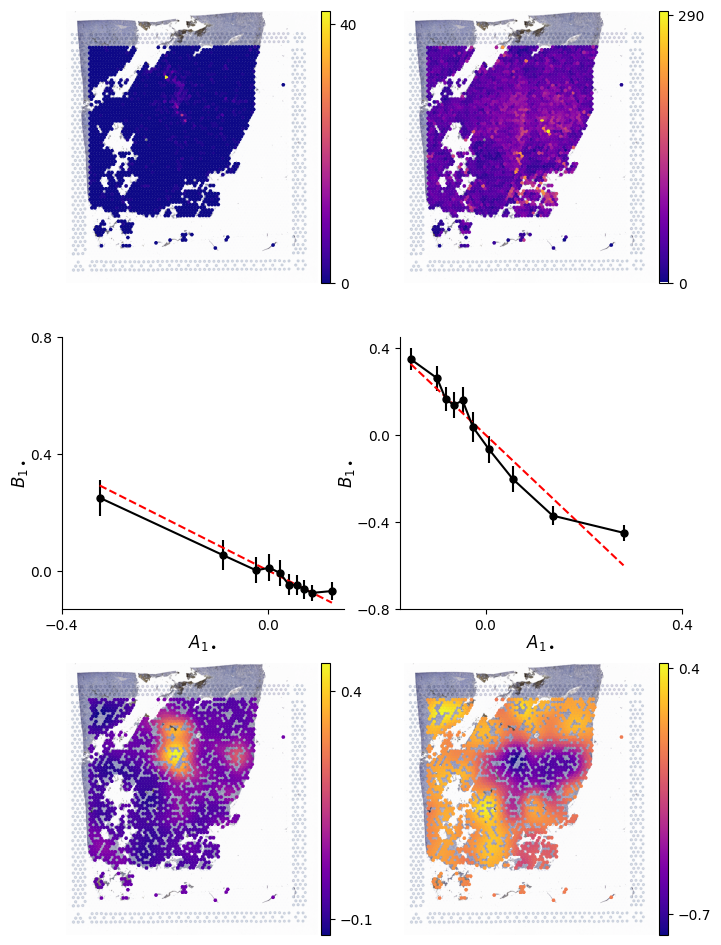

In [5]:
data_directory = 'results/data' # directory with h5ad adata files
gene_list = ['LHB', 'CLU']
slide = 'Vf9'

nrows = 3
ncols = len(gene_list)
fig, axes = plt.subplots(nrows, ncols, figsize = (ncols*4, nrows*4)) #, layout = 'constrained')

adata = sc.read_h5ad(f'{data_directory}/{slide}.h5ad')
np.random.seed(23)
index_train_set = np.random.uniform(0, 1, adata.shape[0]) < 0.3
adata_test = adata[~index_train_set].copy()
q_X = 2**(-7)


for j in range(ncols):
    gene = gene_list[j]

    # First row, display gene expression
    i = 0
    ax = axes[i,j]
    ax = plot_over_tissue(gene, adata, ax, cbar = True, cmap = cmap)
    cbar = ax.collections[0].colorbar
    cbar.set_ticks([0, np.floor(adata[:,gene].X.max()/10)*10])


    # Second row A against B for best bandwidth X
    i = 1
    ax = axes[i,j]
    A, B, beta, Bpred, t, p = compute_A_B_beta_Bpred(adata, index_train_set, gene, q_X = q_X)
    x, y, yerr = compute_B_cond_A_bins(A, B, 10)
    ax.errorbar(x, y, yerr = yerr, ls = '-', marker = marker, ms = ms, color = 'black')     # Plot A against B
    ax.plot(x, x*beta[0], 'r',  ls = '--')     # Plot A against B prediction
    if j == 0:
        ax.set(yticks = [0, 0.4, 0.8], xticks = [-.4, 0])
    if j == 1:
        ax.set(yticks = [-.8, -.4, 0, .4 ], xticks = [0, .4] )
    ax.set_xlabel(f'$A_{{{1} \\bullet}}$', fontsize = fontsize, labelpad = 0)
    ax.set_ylabel(f'$B_{{{1} \\bullet}}$', fontsize = fontsize, labelpad = 0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)



    # Third row, plot B prediction against X
    i = 2
    ax = axes[i,j]
    adata_test.obs['Bpred'] = Bpred
    ax = plot_over_tissue('Bpred', adata_test, ax, cmap = cmap)
    cbar_label = f'$\\hat{{B}}_{{{1} \\bullet}}$'
    cbar = ax.collections[0].colorbar
    cbar.set_ticks([np.min((np.ceil(Bpred.min()*10)/10, -.1)), np.max((np.floor(Bpred.max()*10)/10, .1))])
    print(f'gene {gene}, p-value = {p}')

# fig.savefig('pituitary_figures.pdf', bbox_inches = 'tight')



# Figure S14

gene LHB, p-value = 6.576319656706468e-34 for log2$q_X$ =-9$
gene CLU, p-value = 1.543466828415884e-147 for log2$q_X$ =-9$
gene LHB, p-value = 1.7093431684431482e-51 for log2$q_X$ =-7$
gene CLU, p-value = 2.477545674551646e-157 for log2$q_X$ =-7$
gene LHB, p-value = 8.449890889959349e-46 for log2$q_X$ =-5$
gene CLU, p-value = 1.095347227310854e-154 for log2$q_X$ =-5$
gene LHB, p-value = 7.541185340033445e-30 for log2$q_X$ =-3$
gene CLU, p-value = 4.2658940127096736e-125 for log2$q_X$ =-3$
gene LHB, p-value = 1.222539054898275e-12 for log2$q_X$ =-1$
gene CLU, p-value = 3.7445856634794554e-64 for log2$q_X$ =-1$


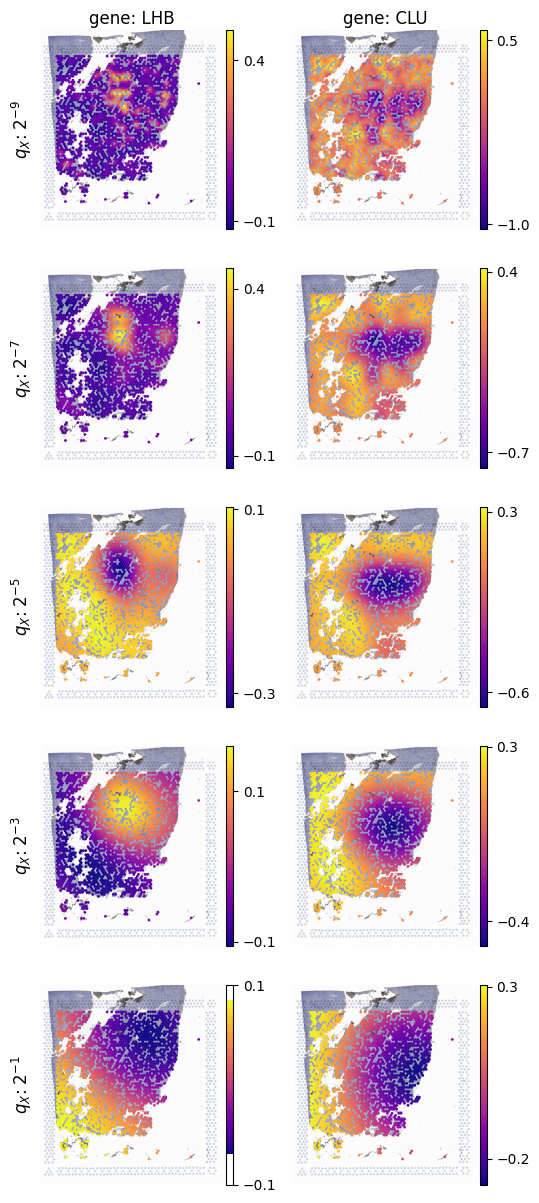

In [ ]:
data_directory = 'results/data' # directory with h5ad adata files
gene_list = ['LHB', 'CLU']
q_X_list = [2**(-9), 2**(-7), 2**(-5), 2**(-3), 2**(-1)]
slide = 'Vf9'

nrows = len(q_X_list)
ncols = len(gene_list)
fig, axes = plt.subplots(nrows, ncols, figsize = (ncols*3, nrows*3)) #, layout = 'constrained')

adata = sc.read_h5ad(f'{data_directory}/{slide}.h5ad')
np.random.seed(23)
index_train_set = np.random.uniform(0, 1, adata.shape[0]) < 0.3
adata_test = adata[~index_train_set].copy()

for i in range(nrows):
    q_X = q_X_list[i]
    for j in range(ncols):
        gene = gene_list[j]
        ax = axes[i,j]

        A, B, beta, Bpred, t, p = compute_A_B_beta_Bpred(adata, index_train_set, gene, q_X = q_X)
        adata_test.obs['Bpred'] = Bpred
        ax = plot_over_tissue('Bpred', adata_test, ax, cmap = cmap)
        cbar_label = f'$\\hat{{B}}_{{{1} \\bullet}}$'
        cbar = ax.collections[0].colorbar
        cbar.set_ticks([np.min((np.ceil(Bpred.min()*10)/10, -.1)), np.max((np.floor(Bpred.max()*10)/10, .1))])
        # cbar.set_ticks([-.3, 0, .3])
        print(f'gene {gene}, p-value = {p} for log2$q_X$ ={int(np.log2(q_X_list[i]))}$')


for i in range(nrows):
    ax = axes[i, 0]
    ax.set_ylabel(f'$q_X$: $2^{{{int(np.log2(q_X_list[i]))}}}$', fontsize = fontsize)
    # ax.yaxis.set_label_position("right", )

for j in range(ncols):
    ax = axes[0, j]
    ax.set_xlabel(f'gene: {gene_list[j]}', fontsize = fontsize)
    ax.xaxis.set_label_position("top")

# fig.savefig('projection_Bpred_vs_X_LHB_CLU_qX.pdf', bbox_inches = 'tight')